# IEEE 39 bus: native Simulink, DPsim ME, and DPsim CS

This notebook compares a dual-interface FMI 3 averaged inverter in the three-phase IEEE 39 bus EMT case. DPsim Model Exchange (ME), DPsim Co-Simulation (CS), and native Simulink use a **matched 50 µs fixed step and 0.2 s duration**. That is 4,000 network intervals and 4,001 logged samples including the initial point.

The native Simulink inverter replays the terminal-voltage trace from the corresponding DPsim run, with the same 125 MW / 80.881 Mvar controller and initialized current. It is an **open-loop component reference**; ME and CS are the two closed-loop network runs. Native Simulink is not presented as a third closed-loop IEEE 39 network.

The first Simulink execution is a compile/cache warm-up and is excluded from the reported per-run replay time. The reported ME replay is the second run; the CS replay follows against its own voltage trace, using the compiled model.

The case retains half of original generator 30's operating point and supplies the other half with the inverter. A 100 MW balanced load connects at bus 39 at 0.170 s.

## Reproduce

From the repository root, run `python3 dpsim-fmi/examples/ieee39_inverter/run_ieee39_comparison.py --run` with MATLAB R2025a and Simulink available. It builds the dual-interface FMU and runner, collects per-component and solver timings for both DPsim modes, then runs the matched-step native replays. Running this notebook reloads the saved outputs.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

repo = Path.cwd()
if not (repo / 'dpsim-fmi/examples/ieee39_inverter/run_ieee39_comparison.py').exists():
    raise FileNotFoundError('Open this notebook with the DPsim repository as its working directory.')
case = repo / 'dpsim-fmi/examples/ieee39_inverter'
build = next((candidate for candidate in (repo / 'build-fmi-cosim', repo / 'build-fmi') if (candidate / 'CMakeCache.txt').is_file()), repo / 'build-fmi-cosim')
data = build / 'ieee39-inverter'
metrics = json.loads((data / 'ieee39_metrics.json').read_text())
timings = metrics['timings']

assert timings['me']['communication_step_s'] == timings['cs']['communication_step_s'] == 50e-6
assert timings['me']['stop_time_s'] == timings['cs']['stop_time_s'] == 0.2
assert all(abs(timings['native_replay'][m]['fixed_step_s'] - 50e-6) < 1e-12 for m in ('me', 'cs'))
assert all(abs(timings['native_replay'][m]['stop_time_s'] - 0.2) < 1e-12 for m in ('me', 'cs'))

runtime_rows = [
    {'Execution': 'DPsim ME', 'Initialization [s]': timings['me']['initialization_runtime_s'], 'Simulation loop [s]': timings['me']['simulation_runtime_s'], 'Total [s]': timings['me']['total_runtime_s'], 'Step [µs]': 50, 'Intervals': 4000},
    {'Execution': 'DPsim CS', 'Initialization [s]': timings['cs']['initialization_runtime_s'], 'Simulation loop [s]': timings['cs']['simulation_runtime_s'], 'Total [s]': timings['cs']['total_runtime_s'], 'Step [µs]': 50, 'Intervals': 4000},
    {'Execution': 'Native Simulink replay (ME trace)', 'Initialization [s]': None, 'Simulation loop [s]': timings['native_replay']['me']['runtime_s'], 'Total [s]': timings['native_replay']['me']['runtime_s'], 'Step [µs]': 50, 'Intervals': 4000},
    {'Execution': 'Native Simulink replay (CS trace)', 'Initialization [s]': None, 'Simulation loop [s]': timings['native_replay']['cs']['runtime_s'], 'Total [s]': timings['native_replay']['cs']['runtime_s'], 'Step [µs]': 50, 'Intervals': 4000},
]
display(pd.DataFrame(runtime_rows).set_index('Execution').round(4))

,Initialization [s],Simulation loop [s],Total [s],Step [µs],Intervals
Execution,,,,,
DPsim ME,0.2753,3.5856,3.8609,50,4000
DPsim CS,0.2744,3.0084,3.2828,50,4000
Native Simulink replay (ME trace),NaN,1.2968,1.2968,50,4000
Native Simulink replay (CS trace),NaN,1.0873,1.0873,50,4000


## Where DPsim time goes

The scheduler profile measures every component's `MnaPreStep` and `MnaPostStep` task, plus the network `.Solve` task. The solver phase file separates numeric KLU solve, RHS assembly, matrix refactorization, and other phases. The ME `.Solve` task also includes FMI nonlinear checks and repeat linearizations, so use `numeric_solve` for the linear algebra comparison. The first table shows the inverter and whole solver task; the second lists pre/post timings for every component.

In [2]:
component_times = pd.read_csv(data / 'component_timing_breakdown.csv')
solver_times = pd.read_csv(data / 'solver_timing_breakdown.csv')
step_times = pd.read_csv(data / 'scheduler_step_timing.csv')

focus = component_times[component_times.component_task.str.contains('Gen30_AveragedInverter|\\.Solve$')]
display(focus[['mode', 'component_task', 'category', 'avg_us', 'total_ms', 'calls']].sort_values(['mode', 'category']))

all_components = component_times[component_times.category.isin(['component_pre_step', 'component_post_step'])]
display(all_components[['mode', 'component_task', 'category', 'avg_us', 'total_ms', 'calls']].sort_values(['mode', 'category', 'total_ms'], ascending=[True, True, False]).reset_index(drop=True))

phase_selection = solver_times[solver_times.phase.isin(['rhs_assembly', 'partial_refactorization', 'numeric_solve', 'matrix_reset_and_variable_stamping', 'node_voltage_propagation'])]
display(phase_selection[['mode', 'phase', 'total_s', 'avg_us', 'calls']].sort_values(['phase', 'mode']))
step_times['scheduler_wall_ms'] = step_times.scheduler_wall_ns / 1e6
step_times['task_execution_ms'] = step_times.task_execution_ns / 1e6
display(step_times.groupby('mode')[['scheduler_wall_ms', 'task_execution_ms']].agg(['mean', 'median', 'max']).round(4))

,mode,component_task,category,avg_us,total_ms,calls
171,CS,Gen30_AveragedInverter.MnaPostStep,component_post_step,1.417,5.671355,4000
172,CS,Gen30_AveragedInverter.MnaPreStep,component_pre_step,2.310,9.242628,4000
161,CS,IEEE39_Inverter_cs.Solve,solver_task,245.496,981.987658,4000
20,ME,Gen30_AveragedInverter.MnaPostStep,component_post_step,2.366,9.466427,4000
22,ME,Gen30_AveragedInverter.MnaPreStep,component_pre_step,40.936,163.745387,4000
3,ME,IEEE39_Inverter_me.Solve,solver_task,334.419,1337.677923,4000


,mode,component_task,category,avg_us,total_ms,calls
0,CS,line16.MnaPostStep,component_post_step,2.355,9.423540,4000
1,CS,line19.MnaPostStep,component_post_step,2.332,9.328598,4000
2,CS,line5.MnaPostStep,component_post_step,2.302,9.211902,4000
3,CS,line1.MnaPostStep,component_post_step,2.300,9.202560,4000
4,CS,line15.MnaPostStep,component_post_step,2.288,9.155931,4000
...,...,...,...,...,...,...
311,ME,load21.MnaPreStep,component_pre_step,1.460,5.843028,4000
312,ME,load19.MnaPreStep,component_pre_step,1.459,5.838749,4000
313,ME,load20.MnaPreStep,component_pre_step,1.455,5.821583,4000
314,ME,load12.MnaPreStep,component_pre_step,1.451,5.804985,4000


,mode,phase,total_s,avg_us,calls
12,CS,matrix_reset_and_variable_stamping,0.029005,7.25133,4000
0,ME,matrix_reset_and_variable_stamping,0.049495,6.18690,8000
13,CS,node_voltage_propagation,0.011486,2.87160,4000
1,ME,node_voltage_propagation,0.012449,3.11216,4000
14,CS,numeric_solve,0.025788,6.44693,4000
2,ME,numeric_solve,0.025601,6.40024,4000
15,CS,partial_refactorization,0.106556,26.63910,4000
3,ME,partial_refactorization,0.202847,25.35580,8000
16,CS,rhs_assembly,0.754162,188.54000,4000
4,ME,rhs_assembly,0.755013,188.75300,4000


scheduler_wall_ms                 task_execution_ms                
                  mean  median     max              mean  median     max
mode                                                                    
CS              0.7461  0.6982  1.7148            0.5546  0.5067  1.4627
ME              0.8902  0.8226  1.8187            0.6980  0.6313  1.5998

## Numerical comparison

Current errors compare each DPsim mode with the native Simulink replay driven by that same DPsim mode's terminal voltage, or compare CS directly with ME. Voltage errors compare closed-loop DPsim ME and CS at selected buses. Peak-base percentages use the appropriate nominal phase peak for current or voltage. The load-step window is 0.170–0.190 s.

In [3]:
post = 'post_startup'
rows = []
for key, label in [('me_vs_native_replay', 'ME vs native replay'), ('cs_vs_native_replay', 'CS vs native replay'), ('cs_vs_me', 'CS vs ME')]:
    m = metrics['current_error'][key][post]
    rows.append({'Comparison': label, 'Max error [A]': m['max_abs'], 'RMS error [A]': m['rms'], 'Max error [% current base]': m['max_abs_percent_base']})
for bus in ['30', '39']:
    m = metrics['bus_voltage_me_vs_cs'][bus][post]
    rows.append({'Comparison': f'CS vs ME, bus {bus} voltage', 'Max error [V]': m['max_abs'], 'RMS error [V]': m['rms'], 'Max error [% voltage base]': m['max_abs_percent_base']})
display(pd.DataFrame(rows).set_index('Comparison').round(6))

transient_rows = []
for key, label in [('me_vs_native_replay', 'ME vs native replay'), ('cs_vs_native_replay', 'CS vs native replay'), ('cs_vs_me', 'CS vs ME')]:
    m = metrics['current_error'][key]['load_step_window']
    transient_rows.append({'Comparison': label, 'Max current error [A]': m['max_abs'], 'RMS current error [A]': m['rms'], 'Max error [% current base]': m['max_abs_percent_base']})
for bus in ['30', '39']:
    m = metrics['bus_voltage_me_vs_cs'][bus]['load_step_window']
    transient_rows.append({'Comparison': f'CS vs ME, bus {bus} voltage', 'Max voltage error [V]': m['max_abs'], 'RMS voltage error [V]': m['rms'], 'Max error [% voltage base]': m['max_abs_percent_base']})
display(pd.DataFrame(transient_rows).set_index('Comparison').round(6))

,Max error [A],RMS error [A],Max error [% current base],Max error [V],RMS error [V],Max error [% voltage base]
Comparison,,,,,,
ME vs native replay,0.559922,0.047921,0.158906,NaN,NaN,NaN
CS vs native replay,1.616644,1.049286,0.458805,NaN,NaN,NaN
CS vs ME,1.493929,1.048794,0.423978,NaN,NaN,NaN
"CS vs ME, bus 30 voltage",NaN,NaN,NaN,0.330871,0.160805,0.000117
"CS vs ME, bus 39 voltage",NaN,NaN,NaN,0.025656,0.010326,0.000009


,Max current error [A],RMS current error [A],Max error [% current base],Max voltage error [V],RMS voltage error [V],Max error [% voltage base]
Comparison,,,,,,
ME vs native replay,0.008513,0.006019,0.002416,NaN,NaN,NaN
CS vs native replay,1.484807,1.049918,0.421390,NaN,NaN,NaN
CS vs ME,1.483012,1.048646,0.420880,NaN,NaN,NaN
"CS vs ME, bus 30 voltage",NaN,NaN,NaN,0.313056,0.212601,0.000111
"CS vs ME, bus 39 voltage",NaN,NaN,NaN,0.024373,0.015574,0.000009


Coupling diagnostics:
{
  "me_max_newton_iterations": 2,
  "me_mean_newton_iterations": 2.0,
  "me_max_reported_residual": 6.7e-05,
  "me_max_internal_steps_per_macro_step": 1,
  "me_fmi_evaluation_requests_total": 112000,
  "me_fmi_evaluation_time_total_s": 0.147255,
  "me_fmi_evaluations_per_network_step": 28.0,
  "me_fmi_evaluation_time_per_network_step_us": 36.81375,
  "cs_do_step_calls": 4000,
  "interpretation": "ME uses SinglePassExplicit as the network coupling policy; its residual is the one-pass mismatch, not a converged Newton residual. CS performs one fmi3DoStep per 50 us network step."
}
Waveforms:


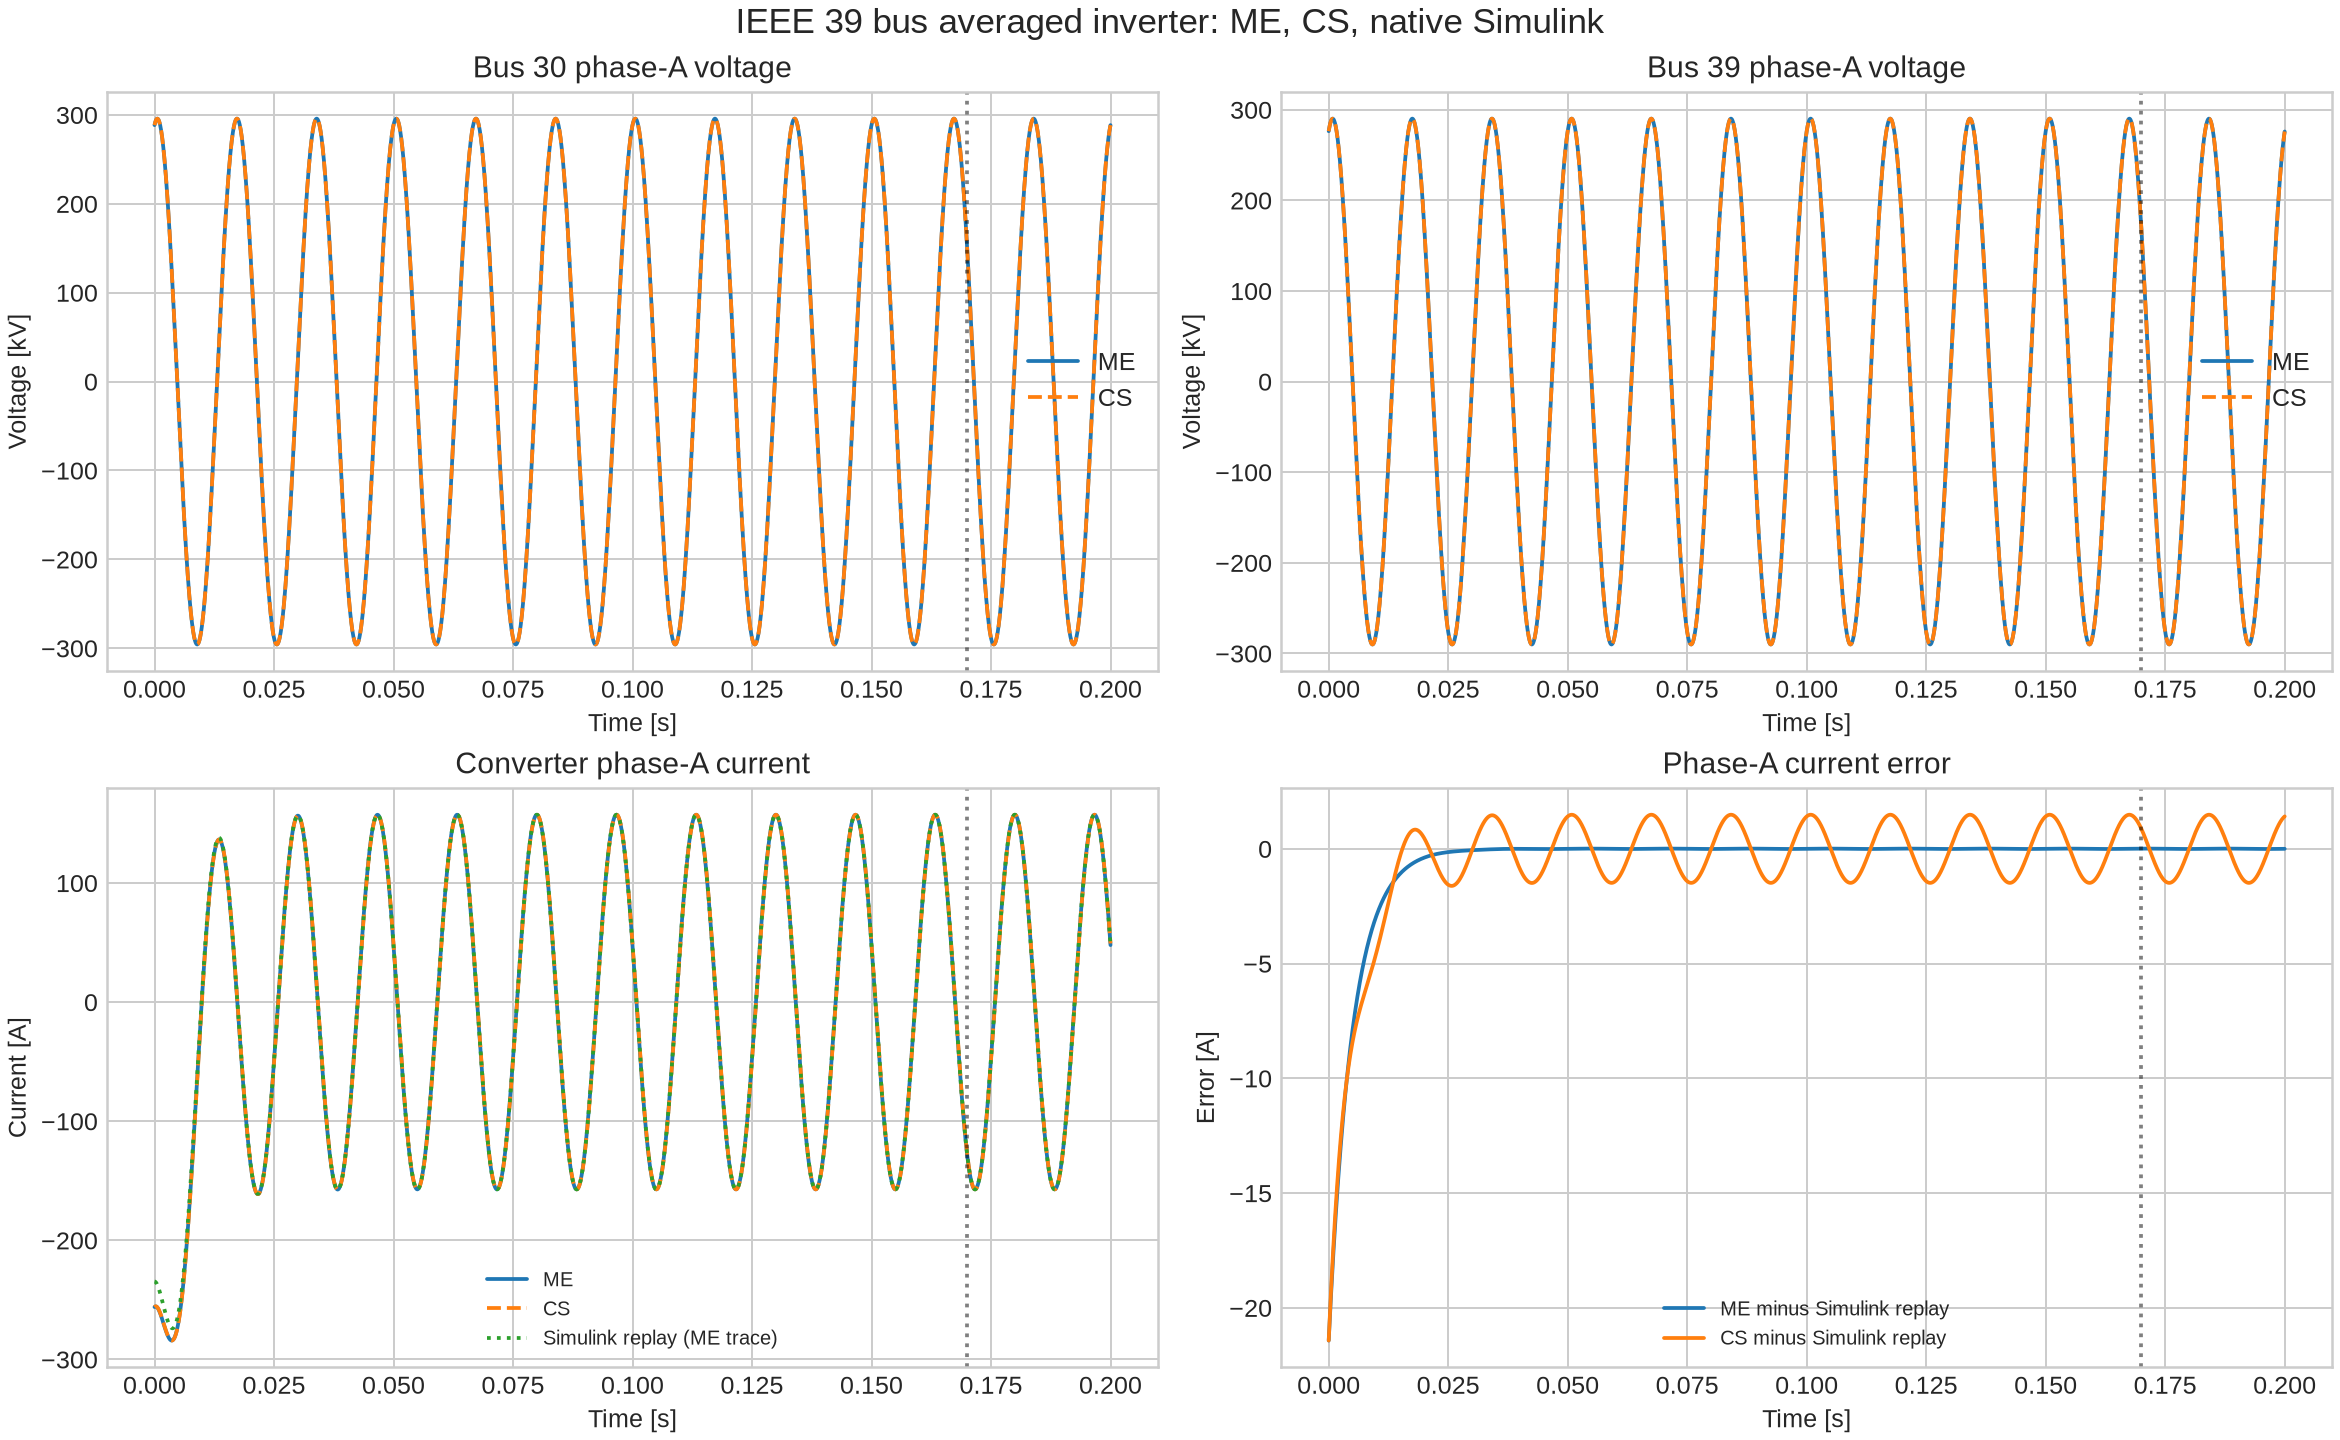

Errors and load-step detail:


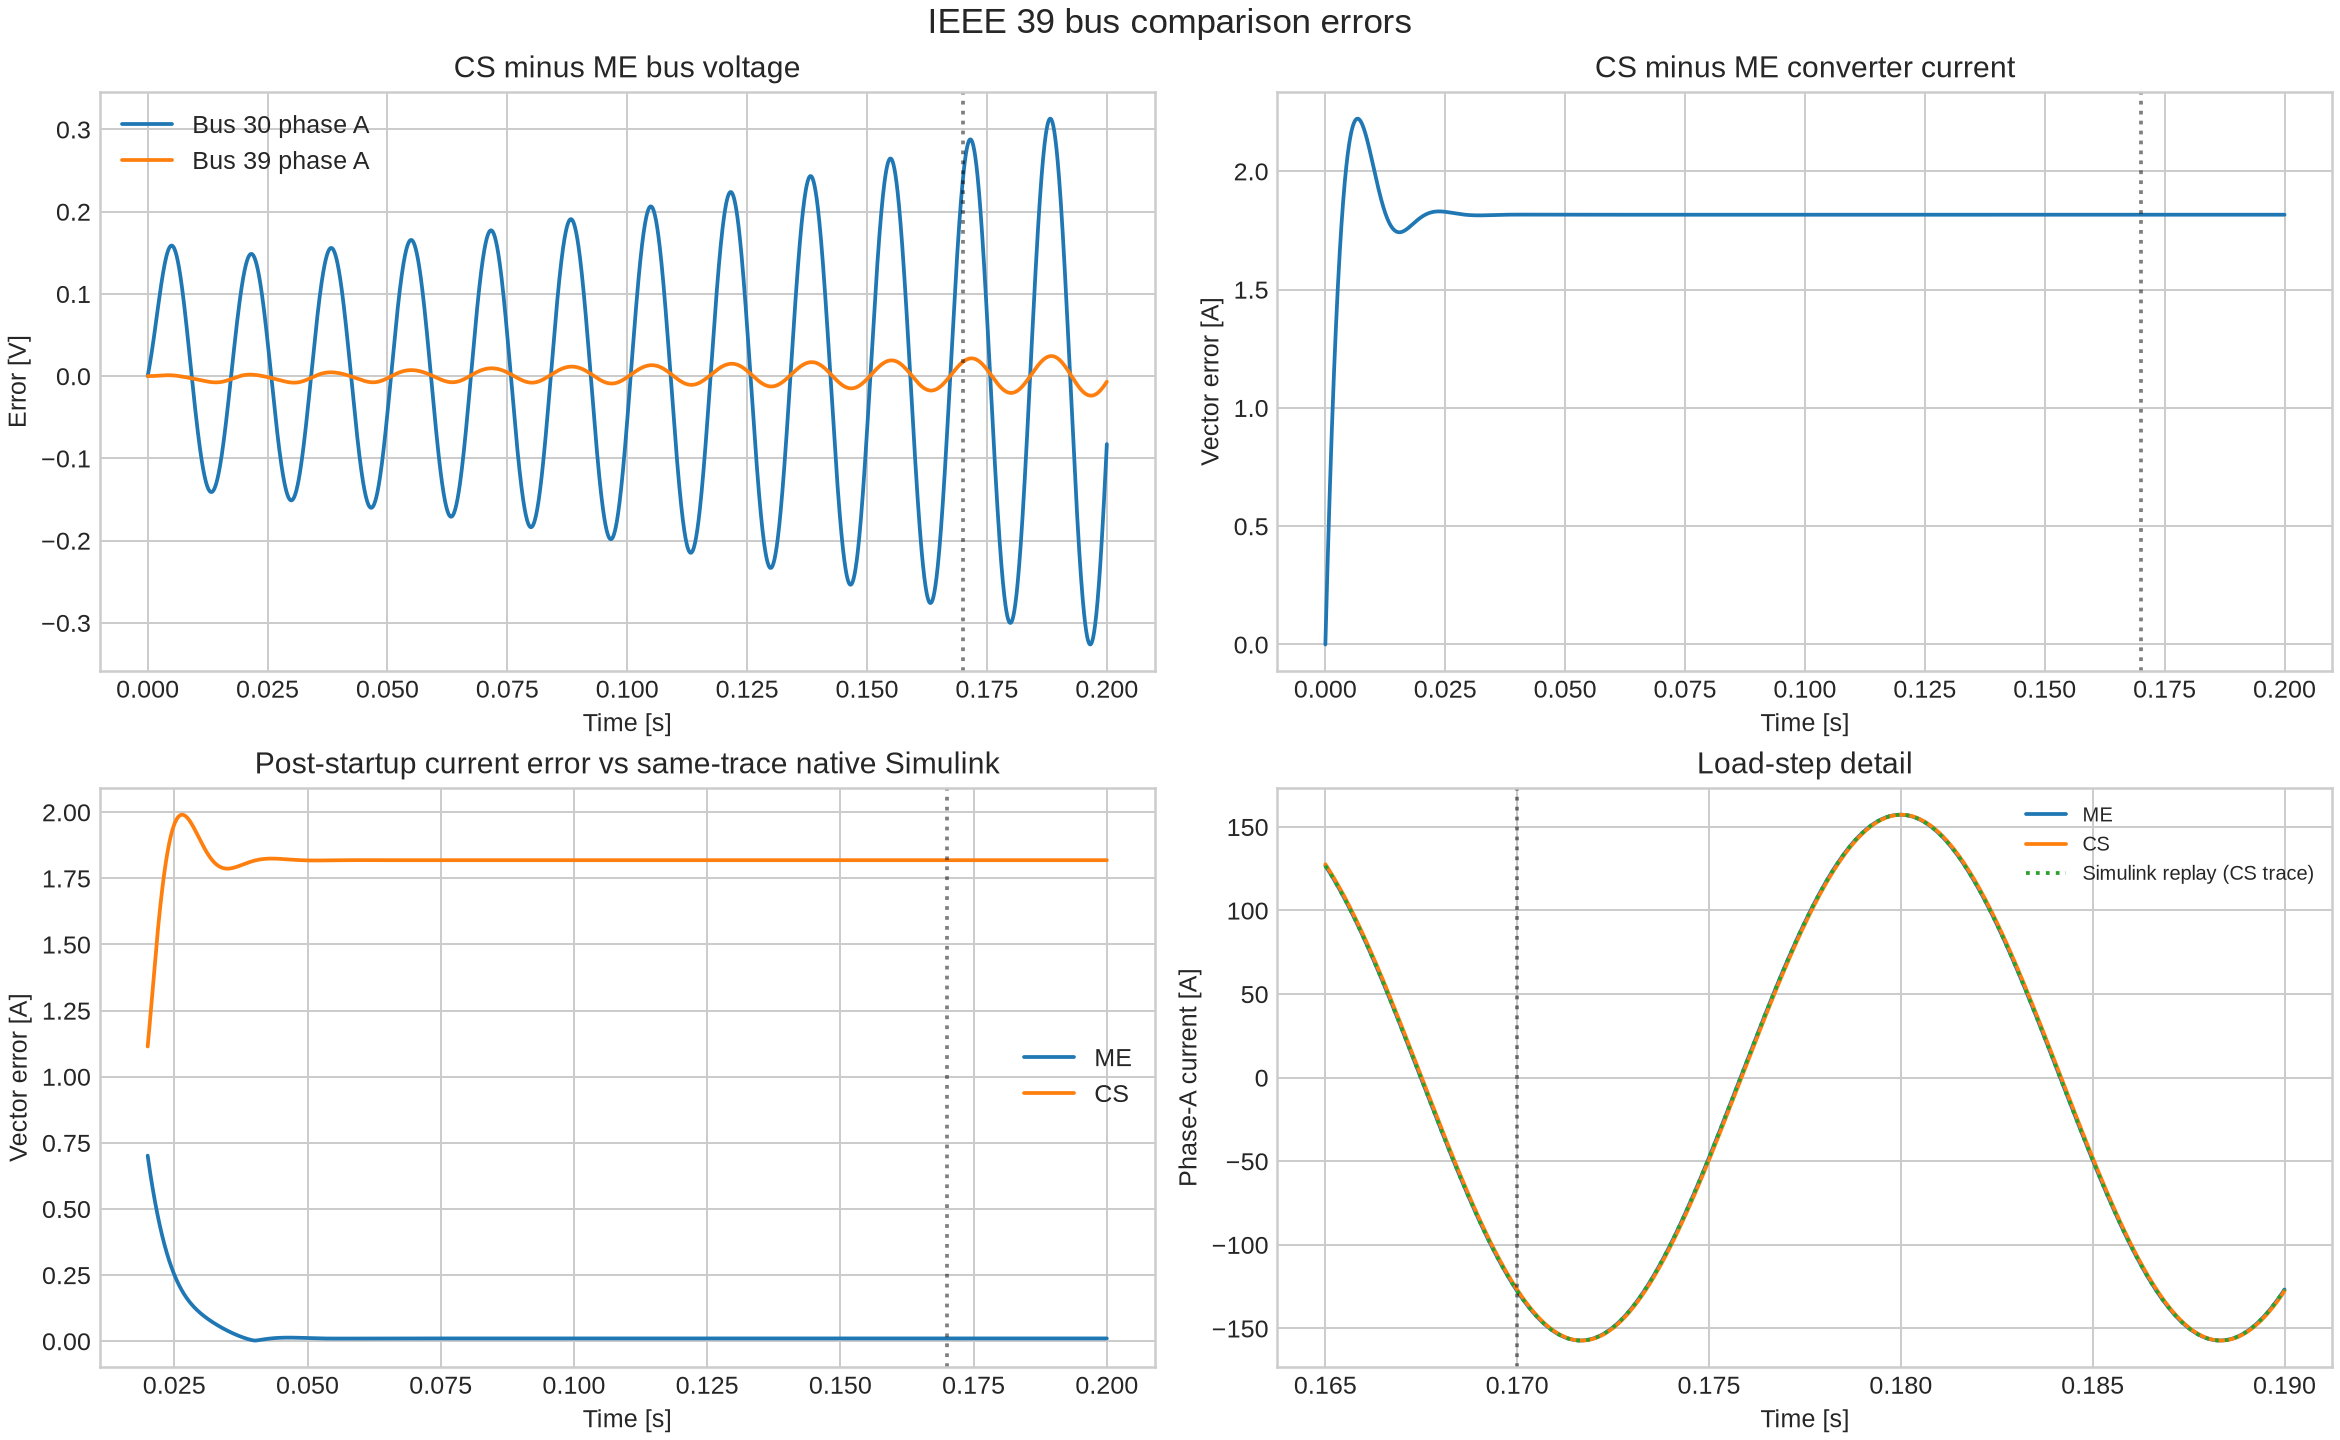

In [4]:
print('Coupling diagnostics:')
print(json.dumps(metrics['coupling_diagnostics'], indent=2))
print('Waveforms:')
display(Image(filename=str(data / 'ieee39_waveforms.png')))
print('Errors and load-step detail:')
display(Image(filename=str(data / 'ieee39_errors.png')))

## Interpretation and limits

- The same dual-interface averaged FMU, network, load event, 50 µs timestep, and 0.2 s stop time are used for both DPsim modes. Native Simulink uses the same fixed-step and physical duration while replaying each run's PCC voltage trace.
- ME uses `SinglePassExplicit`; its logged residual is a one-pass coupling mismatch, not a converged Newton residual. CS makes one `fmi3DoStep` per network interval.
- Native timings exclude the first compile/cache warm-up. The native execution remains an open-loop inverter replay, not a closed-loop full-grid Simulink run.
- The switched MathWorks inverter export required an external execution tool and had no standalone binary. The runnable comparison uses the self-contained averaged dual ME/CS FMU.
- DPsim runtimes include equal task and solver profiling instrumentation in both modes. Native replay and batch runtimes are separate; batch wall time includes MATLAB startup and warm-up.